include(joinpath(@__DIR__, "..", "..", "src", "paths.jl"))
# Adjacent Swaps

In [ ]:
ENV["GKSwstype"] = "100"
using Combinatorics
using Plots
using Plots.PlotMeasures
using Random
using Printf

figures_dir = figure_dir("landscape", "exact")
mkpath(figures_dir)

# ==============================================================================
# 1. Exact MFPT Solver & Swap Distance Calculator
# ==============================================================================
function calculate_MFPT(b::Vector{Float64})
    N_minus_1 = length(b)
    tau = zeros(Float64, N_minus_1)
    tau[1] = 1.0 / b[1]
    @inbounds for m in 2:N_minus_1
        x_m = (1.0 - b[m]) / b[m]
        tau[m] = (1.0 / b[m]) + x_m * tau[m-1]
    end
    return sum(tau)
end

function kendall_tau_distance(p1::Vector{Int}, p2::Vector{Int})
    pos = Dict{Int, Int}()
    for (i, v) in enumerate(p1)
        pos[v] = i
    end
    
    mapped = [pos[v] for v in p2]
    inv_count = 0
    for i in 1:length(mapped)
        for j in (i+1):length(mapped)
            if mapped[i] > mapped[j]
                inv_count += 1
            end
        end
    end
    return inv_count
end

# ==============================================================================
# 2. Phase Space Topology Analyzer
# ==============================================================================
function analyze_landscape(b_base::Vector{Float64})
    N_minus_1 = length(b_base)
    all_perms = collect(permutations(1:N_minus_1))
    
    mfpt_map = Dict{Vector{Int}, Float64}()
    for p in all_perms
        mfpt_map[p] = calculate_MFPT(b_base[p])
    end

    global_min_perm = all_perms[1]
    global_min_mfpt = mfpt_map[global_min_perm]
    for p in all_perms
        if mfpt_map[p] < global_min_mfpt
            global_min_mfpt = mfpt_map[p]
            global_min_perm = p
        end
    end

    local_minima = Vector{Vector{Int}}()
    distances = Vector{Int}()
    
    for p in all_perms
        current_mfpt = mfpt_map[p]
        is_local_min = true
        
        for i in 1:(N_minus_1 - 1)
            neighbor = copy(p)
            neighbor[i], neighbor[i+1] = neighbor[i+1], neighbor[i]
            
            if mfpt_map[neighbor] < current_mfpt
                is_local_min = false
                break
            end
        end
        
        if is_local_min
            push!(local_minima, p)
            push!(distances, kendall_tau_distance(p, global_min_perm))
        end
    end

    avg_distance = isempty(distances) ? 0.0 : sum(distances) / length(distances)
    max_distance = isempty(distances) ? 0 : maximum(distances)
    
    return length(local_minima), avg_distance, max_distance
end

# ==============================================================================
# 3. Execution & Scaling Analysis
# ==============================================================================
function run_scaling_analysis(N_range::UnitRange{Int})
    Random.seed!(42)
    
    counts_low = Float64[]; avg_dist_low = Float64[]; max_dist_low = Float64[]
    counts_high = Float64[]; avg_dist_high = Float64[]; max_dist_high = Float64[]
    
    println("Starting Topological Analysis for N = $(N_range[1]) to $(N_range[end])...")
    
    for N in N_range
        println("Processing N = $N ($(factorial(N-1)) states)...")
        
        b_low = rand(N - 1) .* 0.5
        c_low, ad_low, md_low = analyze_landscape(b_low)
        push!(counts_low, c_low); push!(avg_dist_low, ad_low); push!(max_dist_low, md_low)
        
        b_high = rand(N - 1) .* 0.5 .+ 0.5
        c_high, ad_high, md_high = analyze_landscape(b_high)
        push!(counts_high, c_high); push!(avg_dist_high, ad_high); push!(max_dist_high, md_high)
    end
    
    N_vals = collect(N_range)
    
    p1 = plot(N_vals, counts_low, yscale=:log10, lw=3, color=:red, marker=:circle,
              label="b ∈ [0, 0.5]", title="Proliferation of Local Minima",
              xlabel="System Size (N)", ylabel="Count (Log Scale)", legend=:topleft, gridalpha=0.3)
    plot!(p1, N_vals, counts_high, lw=3, color=:blue, marker=:square, label="b ∈ [0.5, 1]")
    
    p2 = plot(N_vals, avg_dist_low, lw=3, color=:red, marker=:circle,
              label="b ∈ [0, 0.5]", title="Avg Adjacent Swaps to Global Min",
              xlabel="System Size (N)", ylabel="Kendall Tau Distance", legend=:topleft, gridalpha=0.3)
    plot!(p2, N_vals, avg_dist_high, lw=3, color=:blue, marker=:square, label="b ∈ [0.5, 1]")
    
    p3 = plot(N_vals, max_dist_low, lw=3, color=:red, marker=:circle, ls=:dash,
              label="b ∈ [0, 0.5]", title="Max Adjacent Swaps to Global Min",
              xlabel="System Size (N)", ylabel="Max Kendall Tau Distance", legend=:topleft, gridalpha=0.3)
    plot!(p3, N_vals, max_dist_high, lw=3, color=:blue, marker=:square, ls=:dash, label="b ∈ [0.5, 1]")
    
    p_grid = plot(p1, p2, p3, layout=(1, 3), size=(1500, 500), margin=5Plots.mm,
                  plot_title="Combinatorial Landscape Topology Constraints", plot_titlefontsize=14)
    
    savefig(p_grid, joinpath(figures_dir, "landscape_scaling.pdf"))
    display(p_grid)
    println("\nTopological analysis complete. Figure saved to: ", joinpath(figures_dir, "landscape_scaling.pdf"))
end

run_scaling_analysis(4:11)

# ==============================================================================
# 4. Phase Space Mapping & Plotting (With Subplot Capping)
# ==============================================================================
function plot_all_minima(N::Int=7, regime::String="low")
    Random.seed!(42)
    
    if regime == "low"
        b_base = rand(N - 1) .* 0.5
        col = :red
        y_limits = (0.0, 0.55)
    else
        b_base = rand(N - 1) .* 0.5 .+ 0.5
        col = :blue
        y_limits = (0.45, 1.0)
    end
    
    all_perms = collect(permutations(1:(N-1)))
    
    mfpt_map = Dict{Vector{Int}, Float64}()
    for p in all_perms
        mfpt_map[p] = calculate_MFPT(b_base[p])
    end

    local_minima = Vector{Vector{Int}}()
    for p in all_perms
        current_mfpt = mfpt_map[p]
        is_local_min = true
        for i in 1:(N-2)
            neighbor = copy(p)
            neighbor[i], neighbor[i+1] = neighbor[i+1], neighbor[i]
            if mfpt_map[neighbor] < current_mfpt
                is_local_min = false
                break
            end
        end
        if is_local_min
            push!(local_minima, p)
        end
    end

    sort!(local_minima, by = p -> mfpt_map[p])
    
    n_minima = length(local_minima)
    n_to_plot = min(n_minima, 100)
    println("Found $n_minima local minima for N=$N in the '$regime' regime. Plotting top $n_to_plot.")
    
    # Scale columns appropriately for large grids
    cols = min(10, n_to_plot)
    rows = max(1, ceil(Int, n_to_plot / cols))
    subplots = []
    
    for (idx, p) in enumerate(local_minima[1:n_to_plot])
        b_min = b_base[p]
        mfpt_val = mfpt_map[p]
        
        if regime == "low"
            mfpt_str = @sprintf("%.2e", mfpt_val)
        else
            mfpt_str = string(round(mfpt_val, digits=2))
        end
        
        title_str = idx == 1 ? "Rank 1 (Global)\nMFPT=$mfpt_str" : "Rank $idx\nMFPT=$mfpt_str"
        
        sub_p = plot(1:(N-1), b_min, st=:stepmid, lw=2, color=col,
                     title=title_str, titlefontsize=7,
                     xlabel= idx > (rows-1)*cols ? "Site Index (i)" : "",
                     ylabel= (idx-1) % cols == 0 ? "Prob b_i" : "",
                     legend=false, gridalpha=0.3, ylims=y_limits,
                     margin=1Plots.mm, xtickfontsize=6, ytickfontsize=6)
        scatter!(sub_p, 1:(N-1), b_min, color=col, ms=2)
        push!(subplots, sub_p)
    end
    
    # Safe padding using framestyle=:none to prevent NDC viewport crashes
    while length(subplots) < rows * cols
        push!(subplots, plot(framestyle=:none, axis=false, grid=false, showaxis=false, margin=0Plots.mm))
    end

    p_grid = plot(subplots..., layout=(rows, cols), size=(cols*250, rows*200),
                  plot_title="Local Minima Configurations (N=$N, $regime regime) [Showing $n_to_plot of $n_minima]", 
                  plot_titlefontsize=14, margin=2Plots.mm)
    
    filepath = joinpath(figures_dir, "all_minima_N$(N)_$(regime).pdf")
    savefig(p_grid, filepath)
    display(p_grid)
    println("Saved plot to $filepath")
end

for N in 4:11
    plot_all_minima(N, "low")
    plot_all_minima(N, "high")
end

# All swaps

Starting Global Topology Analysis for N = 4 to 11...
Processing N = 4 (6 states)...
Processing N = 5 (24 states)...
Processing N = 6 (120 states)...
Processing N = 7 (720 states)...
Processing N = 8 (5040 states)...
Processing N = 9 (40320 states)...
Processing N = 10 (362880 states)...
Processing N = 11 (3628800 states)...


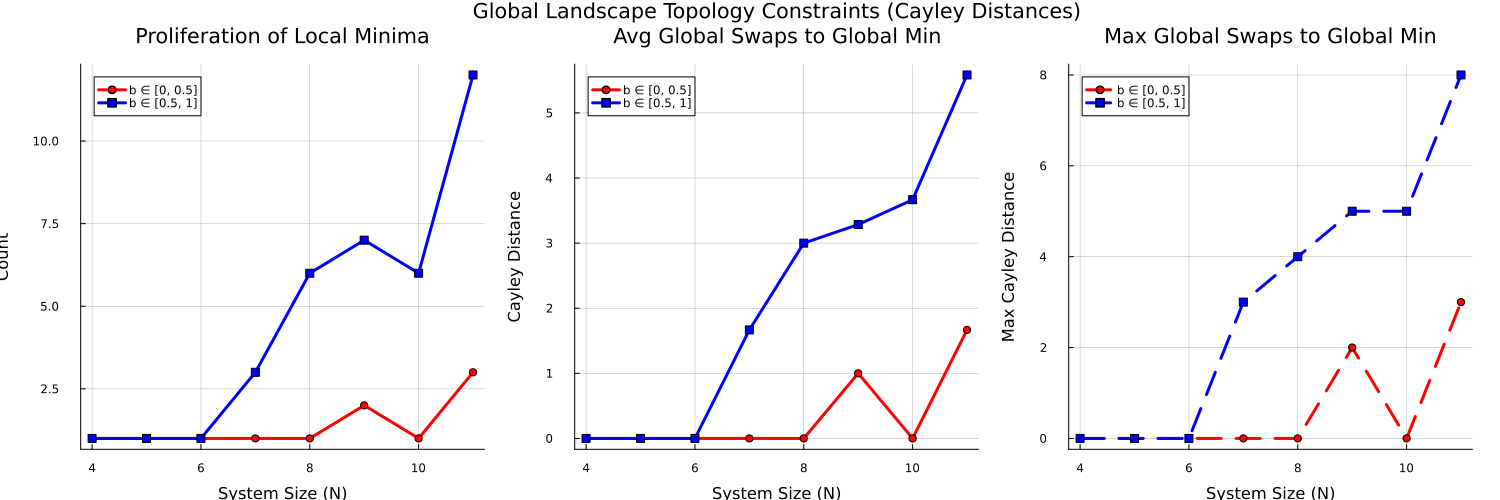


Topological analysis complete. Figure saved to: c:\Users\gerar\Desktop\Escola\Universitat\PhD\Recerca\disordered_fpt\code\Gerard\figures\exhaustive_cayley\landscape_scaling_global.pdf


In [2]:
ENV["GKSwstype"] = "100"
using Combinatorics
using Plots
using Plots.PlotMeasures
using Random
using Printf

figures_dir = figure_dir("landscape", "exact")
mkpath(figures_dir)

# ==============================================================================
# 1. Exact MFPT Solver & Global Swap (Cayley) Distance Calculator
# ==============================================================================
function calculate_MFPT(b::Vector{Float64})
    N_minus_1 = length(b)
    tau = zeros(Float64, N_minus_1)
    tau[1] = 1.0 / b[1]
    @inbounds for m in 2:N_minus_1
        x_m = (1.0 - b[m]) / b[m]
        tau[m] = (1.0 / b[m]) + x_m * tau[m-1]
    end
    return sum(tau)
end

function cayley_distance(p1::Vector{Int}, p2::Vector{Int})
    # Calculates the minimum number of ANY swaps to turn p1 into p2 (Length - Cycles)
    n = length(p1)
    pos = Dict{Int, Int}()
    for (i, v) in enumerate(p1)
        pos[v] = i
    end
    
    mapped = [pos[v] for v in p2]
    visited = falses(n)
    cycles = 0
    
    for i in 1:n
        if !visited[i]
            cycles += 1
            curr = i
            while !visited[curr]
                visited[curr] = true
                curr = mapped[curr]
            end
        end
    end
    return n - cycles
end

# ==============================================================================
# 2. Phase Space Topology Analyzer (Global Swaps)
# ==============================================================================
function analyze_landscape_global(b_base::Vector{Float64})
    N_minus_1 = length(b_base)
    all_perms = collect(permutations(1:N_minus_1))
    
    mfpt_map = Dict{Vector{Int}, Float64}()
    for p in all_perms
        mfpt_map[p] = calculate_MFPT(b_base[p])
    end

    global_min_perm = all_perms[1]
    global_min_mfpt = mfpt_map[global_min_perm]
    for p in all_perms
        if mfpt_map[p] < global_min_mfpt
            global_min_mfpt = mfpt_map[p]
            global_min_perm = p
        end
    end

    local_minima = Vector{Vector{Int}}()
    distances = Vector{Int}()
    
    for p in all_perms
        current_mfpt = mfpt_map[p]
        is_local_min = true
        
        # Check all (N-1)*(N-2)/2 possible global pair swaps
        for i in 1:(N_minus_1 - 1)
            for j in (i+1):N_minus_1
                neighbor = copy(p)
                neighbor[i], neighbor[j] = neighbor[j], neighbor[i]
                
                if mfpt_map[neighbor] < current_mfpt
                    is_local_min = false
                    break
                end
            end
            if !is_local_min
                break
            end
        end
        
        if is_local_min
            push!(local_minima, p)
            push!(distances, cayley_distance(p, global_min_perm))
        end
    end

    avg_distance = isempty(distances) ? 0.0 : sum(distances) / length(distances)
    max_distance = isempty(distances) ? 0 : maximum(distances)
    
    return length(local_minima), avg_distance, max_distance
end

# ==============================================================================
# 3. Execution & Scaling Analysis
# ==============================================================================
function run_scaling_analysis_global(N_range::UnitRange{Int})
    Random.seed!(42)
    
    counts_low = Float64[]; avg_dist_low = Float64[]; max_dist_low = Float64[]
    counts_high = Float64[]; avg_dist_high = Float64[]; max_dist_high = Float64[]
    
    println("Starting Global Topology Analysis for N = $(N_range[1]) to $(N_range[end])...")
    
    for N in N_range
        println("Processing N = $N ($(factorial(N-1)) states)...")
        
        b_low = rand(N - 1) .* 0.5
        c_low, ad_low, md_low = analyze_landscape_global(b_low)
        push!(counts_low, c_low); push!(avg_dist_low, ad_low); push!(max_dist_low, md_low)
        
        b_high = rand(N - 1) .* 0.5 .+ 0.5
        c_high, ad_high, md_high = analyze_landscape_global(b_high)
        push!(counts_high, c_high); push!(avg_dist_high, ad_high); push!(max_dist_high, md_high)
    end
    
    N_vals = collect(N_range)
    
    p1 = plot(N_vals, counts_low, lw=3, color=:red, marker=:circle,
              label="b ∈ [0, 0.5]", title="Proliferation of Local Minima",
              xlabel="System Size (N)", ylabel="Count", legend=:topleft, gridalpha=0.3)
    plot!(p1, N_vals, counts_high, lw=3, color=:blue, marker=:square, label="b ∈ [0.5, 1]")
    
    p2 = plot(N_vals, avg_dist_low, lw=3, color=:red, marker=:circle,
              label="b ∈ [0, 0.5]", title="Avg Global Swaps to Global Min",
              xlabel="System Size (N)", ylabel="Cayley Distance", legend=:topleft, gridalpha=0.3)
    plot!(p2, N_vals, avg_dist_high, lw=3, color=:blue, marker=:square, label="b ∈ [0.5, 1]")
    
    p3 = plot(N_vals, max_dist_low, lw=3, color=:red, marker=:circle, ls=:dash,
              label="b ∈ [0, 0.5]", title="Max Global Swaps to Global Min",
              xlabel="System Size (N)", ylabel="Max Cayley Distance", legend=:topleft, gridalpha=0.3)
    plot!(p3, N_vals, max_dist_high, lw=3, color=:blue, marker=:square, ls=:dash, label="b ∈ [0.5, 1]")
    
    p_grid = plot(p1, p2, p3, layout=(1, 3), size=(1500, 500), margin=5Plots.mm,
                  plot_title="Global Landscape Topology Constraints (Cayley Distances)", plot_titlefontsize=14)
    
    savefig(p_grid, joinpath(figures_dir, "landscape_scaling_global.pdf"))
    display(p_grid)
    println("\nTopological analysis complete. Figure saved to: ", joinpath(figures_dir, "landscape_scaling_global.pdf"))
end

run_scaling_analysis_global(4:11)